## Zadanie 1

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

data = pd.read_csv("stroke_zaj1.csv", decimal=",", sep=";")
print(data.head())

   gender  age  hypertension  heart_disease ever_married      work_type  \
0    Male   67             0              1          Yes        Private   
1    Male   80             0              1          Yes        Private   
2  Female   49             0              0          Yes        Private   
3  Female   79             1              0          Yes  Self-employed   
4    Male   81             0              0          Yes        Private   

  Residence_type  avg_glucose_level   bmi   smoking_status  stroke  
0          Urban             228.69  36.6  formerly smoked       1  
1          Rural             105.92  32.5     never smoked       1  
2            NaN             171.23  34.4           smokes       1  
3          Rural             174.12  24.0     never smoked       1  
4          Urban             186.21  29.0  formerly smoked       1  


In [ ]:
# Sprawdzenie typów danych i ile jest obserwacji
print(data.shape)
data.info()

In [ ]:
# Podstawowe statystyki dla zmiennych liczbowych
print(data.describe())

In [ ]:
# Sprawdzenie wartości i liczebności w kolumnach kategorycznych
for kolumna in data.select_dtypes(include="object").columns:
    print("\n")
    print(data[kolumna].value_counts(dropna=False))

In [ ]:
# Sprawdzenie, w których kolumnach są braki danych
braki = data.isna().sum()
print(braki[braki > 0])

Brakujące wartości można uzupełnić na kilka sposobów. Dla zmiennych liczbowych porównuję średnią i medianę, a dla zmiennych kategorycznych najczęściej występującą wartość. Mediana jest mniej wrażliwa na wartości skrajne niż średnia.

In [ ]:
# Zapisanie statystyk przed uzupełnieniem braków
kolumny_liczbowe = data.select_dtypes(include=np.number).columns.drop("stroke")
statystyki_przed = data[kolumny_liczbowe].agg(["mean", "median", "std"]).T
statystyki_przed

In [ ]:
# Uzupełnienie braków w kopiach danych, żeby móc porównać różne metody
data_srednia = data.copy()
data_mediana = data.copy()
data_moda = data.copy()

for kolumna in kolumny_liczbowe:
    data_srednia[kolumna] = data_srednia[kolumna].fillna(data_srednia[kolumna].mean())
    data_mediana[kolumna] = data_mediana[kolumna].fillna(data_mediana[kolumna].median())

kolumny_kategoryczne = data.select_dtypes(include="object").columns
for kolumna in kolumny_kategoryczne:
    data_moda[kolumna] = data_moda[kolumna].fillna(data_moda[kolumna].mode()[0])

In [ ]:
# Porównanie statystyk przed uzupełnieniem braków i po zastosowaniu średniej oraz mediany
porownanie = pd.concat({
    "Przed": data[kolumny_liczbowe].agg(["mean", "median", "std"]).T,
    "Średnia": data_srednia[kolumny_liczbowe].agg(["mean", "median", "std"]).T,
    "Mediana": data_mediana[kolumny_liczbowe].agg(["mean", "median", "std"]).T
}, axis=1)

porownanie.round(2)

In [ ]:
# Rozkład przykładowej zmiennej przed uzupełnieniem braków i po nim
kolumna = "bmi"

fig, osie = plt.subplots(1, 3, figsize=(14, 4))
data[kolumna].dropna().hist(ax=osie[0], bins=20)
osie[0].set_title("Przed uzupełnieniem")
data_srednia[kolumna].hist(ax=osie[1], bins=20)
osie[1].set_title("Uzupełnienie średnią")
data_mediana[kolumna].hist(ax=osie[2], bins=20)
osie[2].set_title("Uzupełnienie medianą")
plt.tight_layout()
plt.show()

Na wykresach widać, że uzupełnianie braków może zmienić rozkład zmiennej. Wartości uzupełnione średnią lub medianą skupiają się w jednym miejscu. Uzupełnienie średnią nie zmienia średniej, a uzupełnienie medianą nie zmienia mediany, ale w obu przypadkach maleje odchylenie standardowe, bo wiele obserwacji trafia dokładnie w środek rozkładu. Mediana jest zwykle lepszym wyborem, gdy rozkład jest skośny albo występują wartości skrajne. Dla zmiennych kategorycznych najlepiej sprawdza się uzupełnienie proporcjonalne.

Podział na zbiór uczący i testowy pozwala ocenić, jak model radzi sobie z danymi, których nie widział podczas uczenia. Zbiór uczący służy do dopasowania modelu, a testowy do sprawdzenia jakości jego przewidywań. Używam podziału 80/20. Parametr `stratify` pomaga zachować podobny udział obu klas `stroke` w obu zbiorach.

In [ ]:
print("Zbiór uczący:", X_train.shape)
print("Zbiór testowy:", X_test.shape)
print("\nUdział klas w całym zbiorze:")
print(y.value_counts(normalize=True).sort_index())
print("\nUdział klas w zbiorze uczącym:")
print(y_train.value_counts(normalize=True).sort_index())
print("\nUdział klas w zbiorze testowym:")
print(y_test.value_counts(normalize=True).sort_index())

In [ ]:
# Podział na zbiór uczący i testowy.
X = data.drop(columns="stroke")
y = data["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_train = X_train.copy()
X_test = X_test.copy()

In [ ]:
# Zmienne liczbowe: mediana wyliczona tylko na zbiorze uczącym
imputer_num = SimpleImputer(strategy="median")
imputer_num.fit(X_train[kolumny_liczbowe])
X_train[kolumny_liczbowe] = imputer_num.transform(X_train[kolumny_liczbowe])
X_test[kolumny_liczbowe] = imputer_num.transform(X_test[kolumny_liczbowe])

In [ ]:
# Zmienne kategoryczne: uzupełnianie proporcjonalne (proporcje ze zbioru uczącego)
rng = np.random.default_rng(42)

for kolumna in kolumny_kategoryczne:
    proporcje = X_train[kolumna].value_counts(normalize=True)

    braki = X_train[kolumna].isna()
    X_train.loc[braki, kolumna] = rng.choice(proporcje.index, size=braki.sum(), p=proporcje.values)

    braki = X_test[kolumna].isna()
    X_test.loc[braki, kolumna] = rng.choice(proporcje.index, size=braki.sum(), p=proporcje.values)

In [ ]:
# Kontrola
print(X_train.isna().sum().sum(), X_test.isna().sum().sum())   # both should be 0

In [ ]:
# Kodowanie zmiennych kategorycznych na wartości liczbowe, aby można było wykorzystać je w modelu
X_train["gender"] = X_train["gender"].map({"Male": 1, "Female": 0})
X_test["gender"] = X_test["gender"].map({"Male": 1, "Female": 0})
X_train["ever_married"] = X_train["ever_married"].map({"Yes": 1, "No": 0})
X_test["ever_married"] = X_test["ever_married"].map({"Yes": 1, "No": 0})

X_train = pd.get_dummies(
    X_train,
    columns=["work_type", "Residence_type", "smoking_status"],
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=["work_type", "Residence_type", "smoking_status"],
    dtype=int
)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
print((X_train.columns == X_test.columns).all())

Macierz błędu (confusion matrix) pokazuje, ile obserwacji zostało sklasyfikowanych poprawnie i ile razy model pomylił klasy. W klasyfikacji binarnej można na jej podstawie wyróżnić prawdziwie dodatnie (TP), prawdziwie ujemne (TN), fałszywie dodatnie (FP) i fałszywie ujemne (FN).

- **Dokładność (accuracy)** – udział wszystkich poprawnych przewidywań.
- **Czułość (recall)** – udział poprawnie wykrytych przypadków udaru wśród wszystkich osób, które miały udar.
- **Specyficzność** – udział poprawnie rozpoznanych osób bez udaru wśród wszystkich osób bez udaru.
- **F1** – średnia harmoniczna precyzji i czułości.

Nie ma jednej miary, która zawsze jest najważniejsza. W tym zadaniu szczególnie warto sprawdzać czułość, bo niski wynik oznacza, że model nie wykrywa wielu przypadków udaru. Sama dokładność może być myląca, ponieważ klasy są niezrównoważone.

In [ ]:
print(X_train.head())

## Zadanie 2

Metoda k-najbliższych sąsiadów (KNN) szuka w zbiorze uczącym `k` obserwacji najbardziej podobnych do nowej obserwacji. Klasa jest wybierana na podstawie głosowania sąsiadów. Małe `k` może powodować nadmierne dopasowanie do danych uczących, a duże `k` może zbyt mocno uśredniać różnice między klasami.

W KNN standaryzacja jest ważna, ponieważ metoda opiera się na odległościach. Bez niej zmienne o większej skali, np. poziom glukozy, mogłyby mieć nieproporcjonalnie duży wpływ na wynik. Zmienne kategoryczne można wykorzystać po zakodowaniu ich, np. metodą one-hot encoding. Wtedy każda kategoria ma własną kolumnę.

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    recall_score, precision_score, f1_score
)

# Standaryzacja danych
# Oba kroki są w pipeline, więc parametry są wyznaczane tylko na zbiorze uczącym.
model_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

model_knn.fit(X_train, y_train)
y_pred = model_knn.predict(X_test)

print("Macierz pomyłek:")
print(confusion_matrix(y_test, y_pred))
print("\nRaport klasyfikacji:")
print(classification_report(y_test, y_pred, zero_division=0))

Powyższe wyniki pokazują, że model poprawnie przewidział 17 zawałów (true positive) oraz nie przewidział 25 zawałów, które miały miejsce (false negative).
Wyniki fałszywie negatywne, to sytuacja, w której informujemy chorego pacjenta, że jest zdrowy, co jest najgorszym możliwym błędem do popełnienia. Pokazuje to, że w danych medycznych czułość to najważniejsza metryka.


Ważne jest też, aby nie patrzeć w takich sytuacjach jedynie na czułość. Jeśli będzie ona wynosiła 1 i pokazywała, że każdy z pacjentów jest objęty ryzykiem zawału, to również nie są to miarodajne dane. Aby uzyskać możliwie najlepszą miarę warto użyć np. miary F1-score, ROC lub AUC.

In [ ]:
# Obliczania specyficzności
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

dokladnosc = accuracy_score(y_test, y_pred)
czulosc = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
specyficznosc = tn / (tn + fp) if (tn + fp) > 0 else 0
f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

print(f"Dokładność: {dokladnosc:.3f}")
print(f"Czułość: {czulosc:.3f}")
print(f"Specyficzność: {specyficznosc:.3f}")
print(f"F1: {f1:.3f}")

Wynik `czułość = 0,405` jest stosunkowo niski - model pomija więcej niż połowę zawałów.

## Zadanie 3

### KNN z ważeniem odległości

W tej wersji sąsiedzi położeni bliżej obserwacji mają większy wpływ na decyzję modelu. Tak jak w przykładzie z zajęć, ustawiam `weights='distance'`. Idealny wynik na zbiorze uczącym nie musi oznaczać, że model będzie równie dobrze działał na nowych danych, dlatego najważniejszy jest wynik na zbiorze testowym.

In [ ]:
# Budowa KNN, w którym wpływ sąsiadów zależy od ich odległości
model_weighted_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5, weights="distance"))
])

model_weighted_knn.fit(X_train, y_train)

# Prognoza
y_train_pred_weighted_knn = model_weighted_knn.predict(X_train)
y_test_pred_weighted_knn = model_weighted_knn.predict(X_test)

# Macierze pomyłek: najpierw klasa rzeczywista, potem przewidywana
print("Zbiór uczący:")
print(confusion_matrix(y_train, y_train_pred_weighted_knn, labels=[0, 1]))

print("\nZbiór testowy:")
print(confusion_matrix(y_test, y_test_pred_weighted_knn, labels=[0, 1]))

print("\nRaport klasyfikacji dla zbioru testowego:")
print(classification_report(y_test, y_test_pred_weighted_knn, labels=[0, 1], zero_division=0))


## Porównanie modeli z zadania 2 i 3

In [46]:
# Tworzenie funkcji, aby nie powtarzać obliczeń
def oblicz_miary(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "dokladnosc": (tp + tn) / (tn + fp + fn + tp),
        "czulosc": tp / (tp + fn),
        "specyficznosc": tn / (tn + fp),
    }

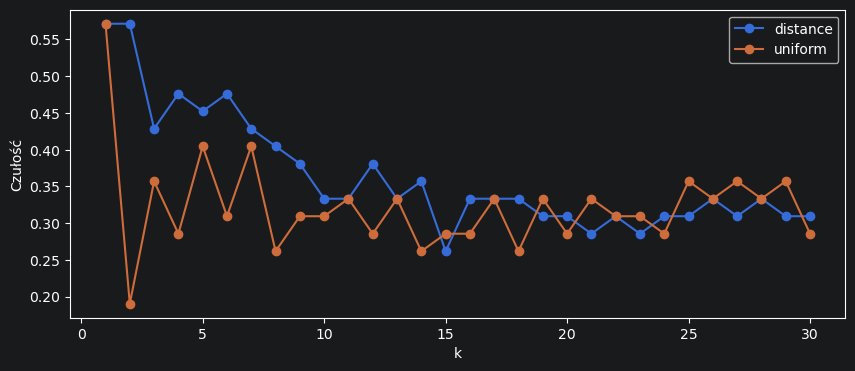

In [47]:
# Pętla do porównania modeli
wyniki = []

for k in range(1, 31):
    for wagi in ["uniform", "distance"]:          # uniform = KNN, distance = ważony KNN
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("knn", KNeighborsClassifier(n_neighbors=k, weights=wagi))
        ])
        model.fit(X_train, y_train)
        miary = oblicz_miary(y_test, model.predict(X_test))
        wyniki.append({"k": k, "wagi": wagi, **miary})

wyniki = pd.DataFrame(wyniki)

# Wykres czułości dla obu metod
fig, ax = plt.subplots(figsize=(10, 4))
for wagi, grupa in wyniki.groupby("wagi"):
    ax.plot(grupa["k"], grupa["czulosc"], marker="o", label=wagi)
ax.set_xlabel("k")
ax.set_ylabel("Czułość")
ax.legend()
plt.show()

Powyższy wykres pokazuje, jak ważne jest odpowiednie dopasowanie wartości `k`. Nieparzyste `k` pozwalają na uniknięcie remisów w sytuacjach z dwiema klasami. W bibliotece sklearn remisy są przypisywane do klasy 0, co znacznie obniża czułość.

W KKNN remisy są praktycznie niemożliwe, więc wybór wartości `k` jest mniej ograniczony.

In [48]:
# Porównanie wyników ze standaryzacją i bez standaryzacji
for skalowanie in [True, False]:
    kroki = [("scaler", StandardScaler())] if skalowanie else []
    model = Pipeline(kroki + [("knn", KNeighborsClassifier(n_neighbors=5))])
    model.fit(X_train, y_train)
    print("Standaryzacja:", skalowanie, oblicz_miary(y_test, model.predict(X_test)))

Standaryzacja: True {'dokladnosc': 0.6341463414634146, 'czulosc': 0.40476190476190477, 'specyficznosc': 0.7530864197530864}
Standaryzacja: False {'dokladnosc': 0.7398373983739838, 'czulosc': 0.6190476190476191, 'specyficznosc': 0.8024691358024691}


Bez standaryzacji zmienne o dużych zakresach dominują w odległościach. W tym przypadku pomogło to wersji bez standaryzacji uzyskać lepsze wyniki. Jest to związane z tym, że wiek i poziom glukozy są silnymi predyktorami.

## Zadanie 4

### Regresja logistyczna

Regresja logistyczna to kolejna metoda klasyfikacji. Zamiast głosowania sąsiadów wyznacza prawdopodobieństwo przynależności do klasy. Używam tego samego podziału na zbiór uczący i testowy, a braki danych i standaryzację umieszczam w `Pipeline`, żeby parametry przygotowania danych były wyznaczane wyłącznie na zbiorze uczącym.

In [50]:
from sklearn.linear_model import LogisticRegression

model_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=42))
])

model_lr.fit(X_train, y_train)

# Predykcja klas na zbiorze testowym
y_pred_lr = model_lr.predict(X_test)
print("Pierwsze przewidziane klasy:")
print(y_pred_lr[:10])

# Prawdopodobieństwa przynależności do klas
y_prob_lr = model_lr.predict_proba(X_test)
print("\nKolejność klas:", model_lr.named_steps["logreg"].classes_)
print("Pierwsze prawdopodobieństwa:")
print(y_prob_lr[:10])

# Ocena jakości klasyfikacji
print("\nMacierz pomyłek:")
print(confusion_matrix(y_test, y_pred_lr, labels=[0, 1]))

print("\nRaport klasyfikacji:")
print(classification_report(y_test, y_pred_lr, labels=[0, 1], zero_division=0))


Pierwsze przewidziane klasy:
[0 0 0 1 1 1 1 0 0 0]

Kolejność klas: [0 1]
Pierwsze prawdopodobieństwa:
[[0.95658194 0.04341806]
 [0.60325643 0.39674357]
 [0.9518829  0.0481171 ]
 [0.27307238 0.72692762]
 [0.43389974 0.56610026]
 [0.37940441 0.62059559]
 [0.10519621 0.89480379]
 [0.77360654 0.22639346]
 [0.77774134 0.22225866]
 [0.90720931 0.09279069]]

Macierz pomyłek:
[[64 17]
 [17 25]]

Raport klasyfikacji:
              precision    recall  f1-score   support

           0       0.79      0.79      0.79        81
           1       0.60      0.60      0.60        42

    accuracy                           0.72       123
   macro avg       0.69      0.69      0.69       123
weighted avg       0.72      0.72      0.72       123



In [51]:
# Obliczenie podstawowych miar jakości regresji logistycznej
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_lr, labels=[0, 1]).ravel()

dokladnosc_lr = accuracy_score(y_test, y_pred_lr)
czulosc_lr = recall_score(y_test, y_pred_lr, pos_label=1, zero_division=0)
specyficznosc_lr = tn / (tn + fp) if (tn + fp) > 0 else 0
f1_lr = f1_score(y_test, y_pred_lr, pos_label=1, zero_division=0)

print(f"Dokładność: {dokladnosc_lr:.3f}")
print(f"Czułość: {czulosc_lr:.3f}")
print(f"Specyficzność: {specyficznosc_lr:.3f}")
print(f"F1: {f1_lr:.3f}")


Dokładność: 0.724
Czułość: 0.595
Specyficzność: 0.790
F1: 0.595


Domyślnie model przypisuje klasę na podstawie progu 0,5. Próg można zmienić, jeśli ważniejsze jest wykrywanie większej liczby przypadków udaru. Niższy próg zwykle zwiększa czułość, ale może też zwiększyć liczbę fałszywie dodatnich przewidywań. Próg należy dobierać na danych walidacyjnych, a nie na podstawie samego zbioru testowego.

In [54]:
# Pobranie prawdopodobieństwa klasy 1, czyli wystąpienia udaru
klasy_lr = model_lr.named_steps["logreg"].classes_
indeks_udaru = list(klasy_lr).index(1)
p_udaru = y_prob_lr[:, indeks_udaru]

# Przykładowy próg odcięcia
prog = 0.3
y_pred_prog = (p_udaru >= prog).astype(int)

print("Próg odcięcia:", prog)
print("Macierz pomyłek:")
print(confusion_matrix(y_test, y_pred_prog, labels=[0, 1]))
print("\nRaport klasyfikacji:")
print(classification_report(y_test, y_pred_prog, labels=[0, 1], zero_division=0))


Próg odcięcia: 0.3
Macierz pomyłek:
[[54 27]
 [10 32]]

Raport klasyfikacji:
              precision    recall  f1-score   support

           0       0.84      0.67      0.74        81
           1       0.54      0.76      0.63        42

    accuracy                           0.70       123
   macro avg       0.69      0.71      0.69       123
weighted avg       0.74      0.70      0.71       123



In [56]:
# Przedstawienie wartości parametrów
logreg = model_lr.named_steps["logreg"]
wspolczynniki = pd.DataFrame({
    "wspolczynnik": logreg.coef_[0],
    "iloraz_szans": np.exp(logreg.coef_[0]),
}, index=X_train.columns).sort_values("wspolczynnik")
print(wspolczynniki.round(3))
print("Wyraz wolny:", logreg.intercept_[0])

                                wspolczynnik  iloraz_szans
work_type_Self-employed               -0.151         0.860
bmi                                   -0.150         0.861
smoking_status_never smoked           -0.137         0.872
ever_married                          -0.107         0.899
work_type_Govt_job                    -0.068         0.934
Residence_type_Rural                  -0.025         0.976
smoking_status_Unknown                -0.003         0.997
Residence_type_Urban                   0.025         1.025
gender                                 0.049         1.050
work_type_Private                      0.057         1.058
smoking_status_formerly smoked         0.082         1.086
heart_disease                          0.088         1.092
smoking_status_smokes                  0.092         1.097
avg_glucose_level                      0.208         1.232
hypertension                           0.254         1.289
work_type_children                     0.256         1.2

Ponieważ dane zostały ustandaryzowane, każdy współczynnik opisuje zmianę logarytmu szans wystąpienia udaru przy wzroście zmiennej o jedno odchylenie standardowe, przy pozostałych zmiennych niezmienionych. Łatwiej interpretować iloraz szans (exp(współczynnik)): wartość powyżej 1 oznacza wzrost szans udaru, a poniżej 1 ich spadek.

Wyraz wolny (−1,02): dla osoby o przeciętnych wartościach wszystkich zmiennych szansa udaru wynosi exp(−1,02) ≈ 0,36, co odpowiada prawdopodobieństwu ok. 26%.

`age` (iloraz szans 5,07): wiek jest zdecydowanie najsilniejszym czynnikiem w modelu. Wzrost wieku o jedno odchylenie standardowe (ok. 21 lat) zwiększa szanse udaru ok. 5-krotnie.

`hypertension` (1,29): nadciśnienie zwiększa szanse udaru; wzrost tej zmiennej o jedno odchylenie standardowe zwiększa szanse o ok. 29%.

`avg_glucose_level` (1,23): wyższy poziom glukozy zwiększa szanse udaru; wzrost o jedno odchylenie standardowe (ok. 53 mg/dL) zwiększa szanse o ok. 23%.

`heart_disease` (1,09) i gender (1,05): współczynniki dodatnie, ale bliskie zera, więc wpływ tych zmiennych w modelu jest niewielki.

`bmi` (0,86) i ever_married (0,90): ilorazy szans poniżej 1, czyli przy stałych pozostałych zmiennych wyższe BMI i bycie w związku małżeńskim wiążą się z nieco niższymi szansami udaru. Wynik ten jest nieintuicyjny. Prawdopodobnie wynika z powiązań z innymi zmiennymi (np. osoby, które były w związku małżeńskim, są zwykle starsze, a wpływ wieku jest już uwzględniony w zmiennej age). Współczynniki opisują efekt przy stałych pozostałych zmiennych, a nie zależność samą w sobie.